# EDA: Image Analysis

## Setup

In [1]:
from pathlib import Path

import kx
import polars as pl

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
IMAGE_DIRS = [DATA_DIR / "HAM10000_images_part_1", DATA_DIR / "HAM10000_images_part_2"]
MASK_DIR = DATA_DIR / "HAM10000_segmentations_lesion_tschandl"
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

SEED = 0
CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

In [3]:
image_paths = pl.DataFrame(
    [
        {"image_id": path.stem, "image_path": str(path)}
        for image_dir in IMAGE_DIRS
        for path in sorted(image_dir.glob("ISIC_*.jpg"))
    ]
)
metadata = (
    pl.read_csv(METADATA_PATH)
    .join(image_paths, on="image_id", how="left", validate="1:1")
    .with_columns(
        (pl.lit(f"{MASK_DIR}/") + pl.col("image_id") + pl.lit("_segmentation.png")).alias("mask_path"),
        pl.col("dx").cast(pl.Enum(CLASSES)),
    )
)

assert metadata.height == 10_015
assert metadata["image_path"].null_count() == 0
assert all(Path(path).exists() for path in metadata["mask_path"])

In [4]:
train = metadata

print(f"Images: {train.height:,} | Lesions: {train['lesion_id'].n_unique():,}")
train["dx"].value_counts().sort("dx")

Images: 10,015 | Lesions: 7,470


dx,count
enum,u32
"""nv""",6705
"""mel""",1113
"""bkl""",1099
"""bcc""",514
"""akiec""",327
"""vasc""",142
"""df""",115


## 1. Visual overview

### 1.1 Per-class sample grids

array([<Axes: ylabel='akiec'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: ylabel='bcc'>, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: ylabel='bkl'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: ylabel='df'>, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: ylabel='mel'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: ylabel='nv'>, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: ylabel='vasc'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >], dtype=object)

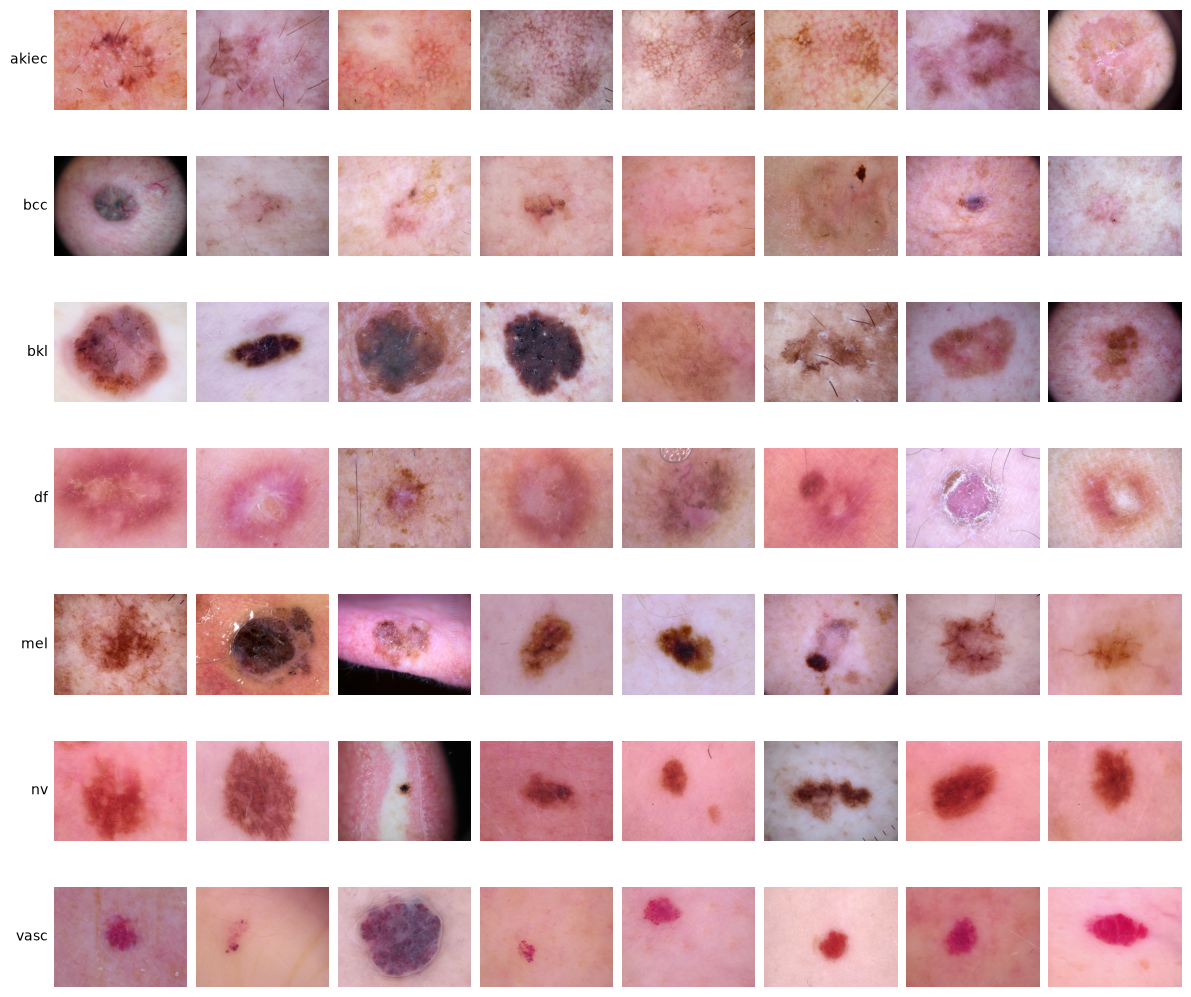

In [5]:
samples = train.unique("lesion_id", keep="first", maintain_order=True)

kx.plot(
    samples["image_path"].to_list(),
    samples["dx"].cast(pl.String).to_list(),
    "imgrid",
    n=8,
    seed=SEED,
    interpolation="antialiased",
)

### 1.2 Variation between images of the same lesion

## 2. Pixel statistics

### 2.1 Colour by class

### 2.2 Brightness, contrast and saturation by class

### 2.3 The same measures by site

## 3. Normalisation

### 3.1 Mean and std on HAM10000 train

### 3.2 Comparison with ImageNet

### 3.3 Recommendation and config export

## 4. Image quality

### 4.1 Sharpness

### 4.2 Exposure

### 4.3 Outlier review

## 5. Artefacts

### 5.1 Dark corner detector

### 5.2 Hair detector

### 5.3 Prevalence by class and site

## 6. Lesion vs surrounding skin

### 6.1 Colour by class

### 6.2 Contrast by class